# Optimizers & Learning-Rate Schedules

## Setup
Tiny-shakespeare, char-level tokenizer, nanoGPT-style model with width as an argument (`head_dim=64` fixed, so `n_head = width // 64`).

In [1]:
import os, math, time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)

if not os.path.exists("input.txt"):
    import requests
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    open("input.txt", "w").write(requests.get(url, timeout=30).text)
TEXT = open("input.txt").read()
CHARS = sorted(set(TEXT))
VOCAB_SIZE = len(CHARS)
STOI = {c: i for i, c in enumerate(CHARS)}

DATA = torch.tensor([STOI[c] for c in TEXT], dtype=torch.long)
TRAIN_DATA = DATA[:int(0.9 * len(DATA))]
BLOCK_SIZE = 64


def get_batch(batch_size=32, block_size=BLOCK_SIZE, generator=None):
    ix = torch.randint(0, len(TRAIN_DATA) - block_size - 1, (batch_size,), generator=generator)
    x = torch.stack([TRAIN_DATA[i:i + block_size] for i in ix])
    y = torch.stack([TRAIN_DATA[i + 1:i + block_size + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

device: mps


In [2]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        self.n_head, self.n_embd = n_head, n_embd
        self.c_attn = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.c_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.drop = nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)).view(1, 1, BLOCK_SIZE, BLOCK_SIZE))

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = self.drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.drop(self.c_proj(y))


class MLP(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.c_fc = nn.Linear(n_embd, 4 * n_embd, bias=False)
        self.c_proj = nn.Linear(4 * n_embd, n_embd, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.c_proj(F.gelu(self.c_fc(x))))


class Block(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd, bias=False)
        self.attn = CausalSelfAttention(n_embd, n_head, dropout)
        self.ln_2 = nn.LayerNorm(n_embd, bias=False)
        self.mlp = MLP(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        return x + self.mlp(self.ln_2(x))


class GPT(nn.Module):
    def __init__(self, n_embd=256, n_layer=4, head_dim=64, dropout=0.1):
        super().__init__()
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(VOCAB_SIZE, n_embd),
            wpe=nn.Embedding(BLOCK_SIZE, n_embd),
            drop=nn.Dropout(dropout),
            h=nn.ModuleList([Block(n_embd, n_embd // head_dim, dropout) for _ in range(n_layer)]),
            ln_f=nn.LayerNorm(n_embd, bias=False),
        ))
        self.lm_head = nn.Linear(n_embd, VOCAB_SIZE, bias=False)
        self.transformer.wte.weight = self.lm_head.weight  # weight tying
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, targets):
        T = idx.size(1)
        x = self.transformer.drop(self.transformer.wte(idx) + self.transformer.wpe(torch.arange(T, device=idx.device)))
        for block in self.transformer.h:
            x = block(x)
        logits = self.lm_head(self.transformer.ln_f(x))
        return F.cross_entropy(logits.view(-1, VOCAB_SIZE), targets.view(-1))

    def num_params(self):
        return sum(p.numel() for p in self.parameters())


def build_model(n_embd=256, n_layer=4, seed=1337):
    torch.manual_seed(seed)
    return GPT(n_embd=n_embd, n_layer=n_layer).to(DEVICE)


print(f"vocab {VOCAB_SIZE}, train tokens {len(TRAIN_DATA):,}, base model params {build_model().num_params():,}")

vocab 65, train tokens 1,003,854, base model params 3,181,056


## Reproduce Adam by hand
One weight (`w=0`), five gradients, raw update rule vs `torch.optim.Adam`.

In [3]:
BETA1, BETA2, EPS, LR = 0.9, 0.999, 1e-8, 0.001
GRADIENTS = [0.50, 0.40, 0.60, 0.45, 0.55]

w, m, v = 0.0, 0.0, 0.0
hand = []
for t, g in enumerate(GRADIENTS, start=1):
    m = BETA1 * m + (1 - BETA1) * g
    v = BETA2 * v + (1 - BETA2) * g ** 2
    m_hat = m / (1 - BETA1 ** t)
    v_hat = v / (1 - BETA2 ** t)
    step = LR * m_hat / (v_hat ** 0.5 + EPS)
    w -= step
    hand.append((t, g, m, v, m_hat, v_hat, step, w))

w_t = torch.tensor(0.0, requires_grad=True)
opt = torch.optim.Adam([w_t], lr=LR, betas=(BETA1, BETA2), eps=EPS)
torch_ws = []
for g in GRADIENTS:
    w_t.grad = torch.tensor(g)
    opt.step()
    torch_ws.append(w_t.item())

print(f"{'t':>2} {'g':>5} {'m':>9} {'v':>9} {'m_hat':>7} {'v_hat':>9} {'step':>9} {'w_hand':>10} {'w_torch':>10} {'diff':>9}")
max_diff = 0.0
for (t, g, m, v, mh, vh, s, w), wt in zip(hand, torch_ws):
    max_diff = max(max_diff, abs(w - wt))
    print(f"{t:>2} {g:>5.2f} {m:>9.6f} {v:>9.6f} {mh:>7.4f} {vh:>9.6f} {s:>9.6f} {w:>10.6f} {wt:>10.6f} {abs(w-wt):>9.2e}")
print(f"\nmax |hand - pytorch|: {max_diff:.2e} -> {'MATCH' if max_diff < 1e-6 else 'MISMATCH'}")

 t     g         m         v   m_hat     v_hat      step     w_hand    w_torch      diff
 1  0.50  0.050000  0.000250  0.5000  0.250000  0.001000  -0.001000  -0.001000  4.89e-11
 2  0.40  0.085000  0.000410  0.4474  0.204977  0.000988  -0.001988  -0.001988  3.01e-11
 3  0.60  0.136500  0.000769  0.5037  0.256703  0.000994  -0.002982  -0.002982  2.74e-11
 4  0.45  0.167850  0.000971  0.4881  0.243132  0.000990  -0.003972  -0.003972  1.65e-10
 5  0.55  0.206065  0.001273  0.5032  0.255030  0.000996  -0.004969  -0.004969  2.71e-10

max |hand - pytorch|: 2.71e-10 -> MATCH


## Disable bias correction, plot 20 steps

 t  corrected  uncorrected  ratio  1-b1^t   1-b2^t
 1   0.001000     0.003162   3.16  0.1000  0.00100
 2   0.001000     0.004249   4.25  0.1900  0.00200
 3   0.001002     0.004962   4.95  0.2710  0.00300
 4   0.001005     0.005466   5.44  0.3439  0.00399
 5   0.001009     0.005850   5.80  0.4095  0.00499
 6   0.000991     0.006002   6.06  0.4686  0.00599
 7   0.000995     0.006216   6.24  0.5217  0.00698
 8   0.001008     0.006428   6.38  0.5695  0.00797
 9   0.001012     0.006550   6.47  0.6126  0.00896
10   0.001010     0.006593   6.53  0.6513  0.00996
11   0.001021     0.006697   6.56  0.6862  0.01095
12   0.001020     0.006703   6.57  0.7176  0.01193
13   0.001029     0.006754   6.56  0.7458  0.01292
14   0.001038     0.006788   6.54  0.7712  0.01391
15   0.001040     0.006765   6.51  0.7941  0.01490
16   0.001020     0.006597   6.46  0.8147  0.01588
17   0.001025     0.006576   6.42  0.8332  0.01686
18   0.001032     0.006564   6.36  0.8499  0.01785
19   0.001044     0.006580   6.

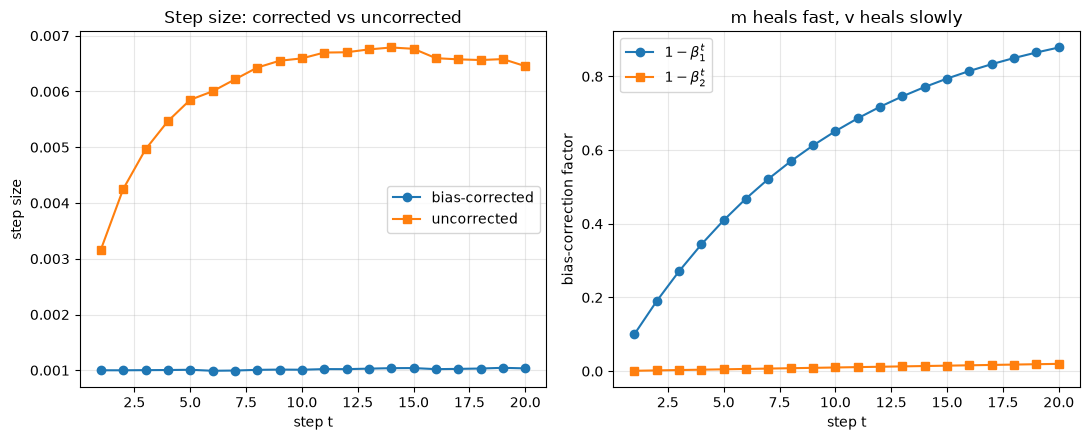

In [4]:
N_STEPS = 20
torch.manual_seed(0)
grads20 = (torch.randn(N_STEPS) * 0.1 + 0.5).tolist()


def adam_steps(gradients, correct_bias):
    m = v = 0.0
    steps = []
    for t, g in enumerate(gradients, start=1):
        m = BETA1 * m + (1 - BETA1) * g
        v = BETA2 * v + (1 - BETA2) * g ** 2
        mh = m / (1 - BETA1 ** t) if correct_bias else m
        vh = v / (1 - BETA2 ** t) if correct_bias else v
        steps.append(LR * mh / (vh ** 0.5 + EPS))
    return steps


steps_c = adam_steps(grads20, True)
steps_u = adam_steps(grads20, False)
ts = list(range(1, N_STEPS + 1))
m_factor = [1 - BETA1 ** t for t in ts]
v_factor = [1 - BETA2 ** t for t in ts]

print(f"{'t':>2} {'corrected':>10} {'uncorrected':>12} {'ratio':>6} {'1-b1^t':>7} {'1-b2^t':>8}")
for t, sc, su, mf, vf in zip(ts, steps_c, steps_u, m_factor, v_factor):
    print(f"{t:>2} {sc:>10.6f} {su:>12.6f} {su/sc:>6.2f} {mf:>7.4f} {vf:>8.5f}")

converge = next((t for t, sc, su in zip(ts, steps_c, steps_u) if abs(sc - su) / sc < 0.05), None)
print(f"\nheal horizon m: {1/(1-BETA1):.0f} steps, v: {1/(1-BETA2):.0f} steps")
print(f"within 5% by step 20: {converge if converge else 'No'}")

# where it would converge if we kept going
steps_c_long = adam_steps(grads20 * 200, True)
steps_u_long = adam_steps(grads20 * 200, False)
converge_long = next((t for t, (sc, su) in enumerate(zip(steps_c_long, steps_u_long), 1) if abs(sc - su) / sc < 0.05), None)
print(f"step where uncorrected comes within 5% of corrected: {converge_long}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(ts, steps_c, "o-", label="bias-corrected")
axes[0].plot(ts, steps_u, "s-", label="uncorrected")
axes[0].set(xlabel="step t", ylabel="step size", title="Step size: corrected vs uncorrected")
axes[1].plot(ts, m_factor, "o-", label=r"$1-\beta_1^t$")
axes[1].plot(ts, v_factor, "s-", label=r"$1-\beta_2^t$")
axes[1].set(xlabel="step t", ylabel="bias-correction factor", title="m heals fast, v heals slowly")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("part2_bias_correction.png", dpi=150)
plt.show()

## Update-to-weight ratio, and when warmup stops mattering
300 steps, 20-step linear warmup + cosine, `||update|| / ||weight||` averaged per layer group (`lm_head` skipped, tied to `wte`).

step    0  lr 1.50e-05  loss 4.2993


step   50  lr 2.92e-04  loss 2.7751


step  100  lr 2.44e-04  loss 2.5763


step  150  lr 1.67e-04  loss 2.4674


step  200  lr 8.49e-05  loss 2.4965


step  250  lr 2.30e-05  loss 2.4237


step  299  lr 9.44e-09  loss 2.4620

bucket          step 1   step 20   step 40  step 300  peak at
embeddings    7.46e-04  5.46e-03  5.36e-03  1.07e-07       30
attention     7.50e-04  2.97e-03  3.91e-03  1.03e-07       30
mlp           7.49e-04  3.60e-03  3.31e-03  9.04e-08       30
layernorm     1.50e-05  8.39e-05  1.07e-04  0.00e+00       30


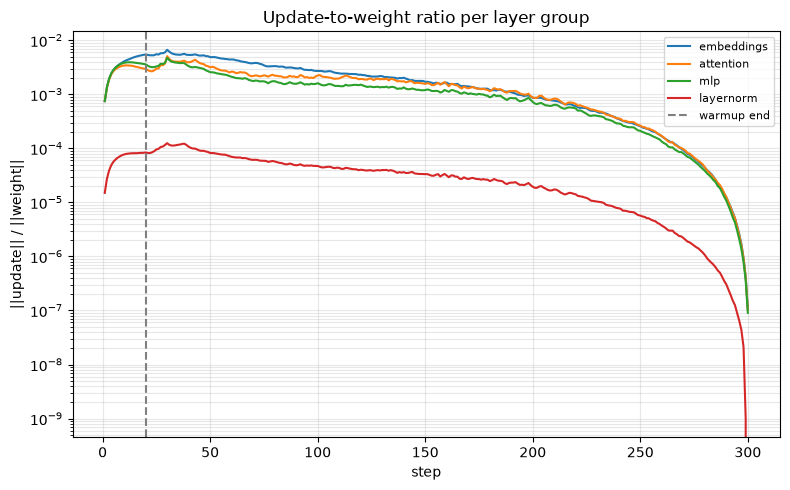

In [5]:
TOTAL_STEPS, WARMUP_STEPS, PEAK_LR, BATCH_SIZE = 300, 20, 3e-4, 32


def warmup_cosine(step, total=TOTAL_STEPS, warmup=WARMUP_STEPS, peak=PEAK_LR):
    if step < warmup:
        return peak * (step + 1) / warmup
    return peak * 0.5 * (1 + math.cos(math.pi * (step - warmup) / (total - warmup)))


def bucket(name):
    for key, b in [("wte", "embeddings"), ("wpe", "embeddings"), ("attn", "attention"), ("mlp", "mlp"), ("ln", "layernorm")]:
        if key in name:
            return b


model = build_model()
optimizer = torch.optim.AdamW(model.parameters(), lr=PEAK_LR)
named = [(n, p) for n, p in model.named_parameters() if n != "lm_head.weight"]
buckets = ["embeddings", "attention", "mlp", "layernorm"]
ratios = {b: [] for b in buckets}

for step in range(TOTAL_STEPS):
    for g in optimizer.param_groups:
        g["lr"] = warmup_cosine(step)
    before = {n: p.detach().clone() for n, p in named}
    loss = model(*get_batch(BATCH_SIZE))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    per = {b: [] for b in buckets}
    for n, p in named:
        per[bucket(n)].append(((p.detach() - before[n]).norm() / before[n].norm().clamp_min(1e-12)).item())
    for b in buckets:
        ratios[b].append(sum(per[b]) / len(per[b]))
    if step % 50 == 0 or step == TOTAL_STEPS - 1:
        print(f"step {step:4d}  lr {warmup_cosine(step):.2e}  loss {loss.item():.4f}")

peak_step = {b: int(np.argmax(ratios[b])) + 1 for b in buckets}
print(f"\n{'bucket':<12} {'step 1':>9} {'step 20':>9} {'step 40':>9} {'step 300':>9} {'peak at':>8}")
for b in buckets:
    r = ratios[b]
    print(f"{b:<12} {r[0]:>9.2e} {r[19]:>9.2e} {r[39]:>9.2e} {r[-1]:>9.2e} {peak_step[b]:>8}")

fig, ax = plt.subplots(figsize=(8, 5))
for b in buckets:
    ax.plot(range(1, TOTAL_STEPS + 1), ratios[b], label=b)
ax.axvline(WARMUP_STEPS, color="gray", ls="--", label="warmup end")
ax.set(yscale="log", xlabel="step", ylabel="||update|| / ||weight||", title="Update-to-weight ratio per layer group")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout()
fig.savefig("part3_warmup_ratio.png", dpi=150)
plt.show()

## Cosine vs WSD, both stopped at step 200 of a 300-step plan
Same model, seed and data order; WSD decays over the last 10%.

 step   cosine      WSD
  200   2.4831   2.4543
  300   2.4458   2.3367

LR at step 200: cosine 7.92e-05 (26% of peak), WSD 3.00e-04 (100% of peak)


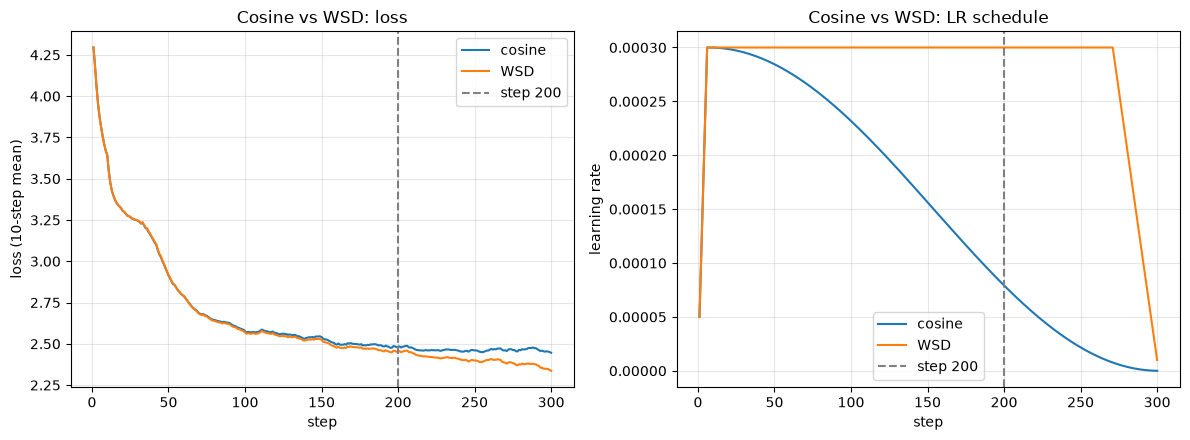

In [6]:
STOP_AT, WARMUP = 200, 6


def cosine_lr(step):
    if step < WARMUP:
        return PEAK_LR * (step + 1) / WARMUP
    return PEAK_LR * 0.5 * (1 + math.cos(math.pi * (step - WARMUP) / (TOTAL_STEPS - WARMUP)))


def wsd_lr(step, decay_frac=0.10):
    decay_start = TOTAL_STEPS * (1 - decay_frac)
    if step < WARMUP:
        return PEAK_LR * (step + 1) / WARMUP
    if step < decay_start:
        return PEAK_LR
    return PEAK_LR * (1 - (step - decay_start) / (TOTAL_STEPS - decay_start))


def train(schedule, seed=1337):
    model = build_model(seed=seed)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=PEAK_LR)
    losses = []
    for step in range(TOTAL_STEPS):
        for g in opt.param_groups:
            g["lr"] = schedule(step)
        loss = model(*get_batch(BATCH_SIZE, generator=gen))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses


def smooth(xs, w=10):
    return [sum(xs[max(0, i - w + 1):i + 1]) / (i - max(0, i - w + 1) + 1) for i in range(len(xs))]


cos_s, wsd_s = smooth(train(cosine_lr)), smooth(train(wsd_lr))
print(f"{'step':>5} {'cosine':>8} {'WSD':>8}")
for s in (STOP_AT, TOTAL_STEPS):
    print(f"{s:>5} {cos_s[s-1]:>8.4f} {wsd_s[s-1]:>8.4f}")
print(f"\nLR at step {STOP_AT}: cosine {cosine_lr(STOP_AT-1):.2e} ({100*cosine_lr(STOP_AT-1)/PEAK_LR:.0f}% of peak), "
      f"WSD {wsd_lr(STOP_AT-1):.2e} ({100*wsd_lr(STOP_AT-1)/PEAK_LR:.0f}% of peak)")

xs = range(1, TOTAL_STEPS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(xs, cos_s, label="cosine"); axes[0].plot(xs, wsd_s, label="WSD")
axes[0].set(xlabel="step", ylabel="loss (10-step mean)", title="Cosine vs WSD: loss")
axes[1].plot(xs, [cosine_lr(s) for s in range(TOTAL_STEPS)], label="cosine")
axes[1].plot(xs, [wsd_lr(s) for s in range(TOTAL_STEPS)], label="WSD")
axes[1].set(xlabel="step", ylabel="learning rate", title="Cosine vs WSD: LR schedule")
for ax in axes:
    ax.axvline(STOP_AT, color="gray", ls="--", label=f"step {STOP_AT}"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("part4_cosine_vs_wsd.png", dpi=150)
plt.show()

## LR sweep at widths 256/512/1024, extrapolated to 4096
3 widths × 6 LRs, 3 layers, 300 steps each, final loss = mean of last 20 steps.

width=  256  lr=1e-04  loss=2.4699


width=  256  lr=2e-04  loss=2.3874


width=  256  lr=5e-04  loss=2.2650


width=  256  lr=1e-03  loss=2.2842


width=  256  lr=2e-03  loss=2.5500


...

width= 1024  lr=2e-04  loss=2.1476


width= 1024  lr=5e-04  loss=2.3071


width= 1024  lr=1e-03  loss=2.5884


width= 1024  lr=2e-03  loss=2.7570


width= 1024  lr=5e-03  loss=3.1039
sweep time: 399s

width   256: params 2,394,112  best lr 5e-04  loss 2.2650
width   512: params 9,506,816  best lr 2e-04  loss 2.2160
width  1024: params 37,888,000  best lr 2e-04  loss 2.1476

fit: log(lr) = -0.661 * log(width) + -4.088   R^2 = 0.750
predicted best LR at width 4096: 6.87e-05


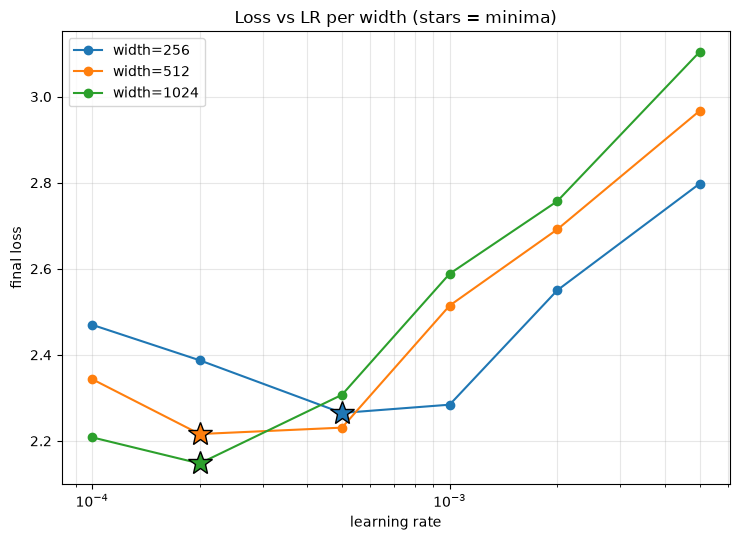

In [7]:
WIDTHS, TARGET_WIDTH = [256, 512, 1024], 4096
LRS = [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3]


def train_one(width, lr, steps=300, seed=1337):
    model = build_model(n_embd=width, n_layer=3, seed=seed)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    losses = []
    for _ in range(steps):
        loss = model(*get_batch(BATCH_SIZE, generator=gen))
        if not torch.isfinite(loss):
            return 20.0, model.num_params()  # diverged
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return float(np.mean(losses[-20:])), model.num_params()


results, params = {}, {}
t0 = time.time()
for w in WIDTHS:
    results[w] = {}
    for lr in LRS:
        results[w][lr], params[w] = train_one(w, lr)
        print(f"width={w:>5}  lr={lr:.0e}  loss={results[w][lr]:.4f}")
print(f"sweep time: {time.time()-t0:.0f}s\n")

best = {w: min(results[w], key=results[w].get) for w in WIDTHS}
for w in WIDTHS:
    print(f"width {w:>5}: params {params[w]:,}  best lr {best[w]:.0e}  loss {results[w][best[w]]:.4f}")

log_w, log_lr = np.log(WIDTHS), np.log([best[w] for w in WIDTHS])
slope, intercept = np.polyfit(log_w, log_lr, 1)
ss_tot = np.sum((log_lr - log_lr.mean()) ** 2)
r2 = 1 - np.sum((log_lr - (slope * log_w + intercept)) ** 2) / ss_tot if ss_tot > 0 else float("nan")
pred_4096 = float(np.exp(slope * np.log(TARGET_WIDTH) + intercept))
print(f"\nfit: log(lr) = {slope:.3f} * log(width) + {intercept:.3f}   R^2 = {r2:.3f}")
print(f"predicted best LR at width {TARGET_WIDTH}: {pred_4096:.2e}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for w in WIDTHS:
    line, = ax.plot(LRS, [results[w][lr] for lr in LRS], "o-", label=f"width={w}")
    ax.plot(best[w], results[w][best[w]], "*", color=line.get_color(), ms=18, mec="black", zorder=5)
ax.set(xscale="log", xlabel="learning rate", ylabel="final loss", title="Loss vs LR per width (stars = minima)")
ax.legend(); ax.grid(alpha=0.3, which="both")
fig.tight_layout()
fig.savefig("part5_mup_sweep.png", dpi=150)
plt.show()